# Exploration statistique comparative des deux datasets de cellules sanguines

Ce notebook a pour seul objectif l'**analyse exploratoire (EDA)** : aucune image n'est modifiée, seuls des **indicateurs statistiques** sont calculés et comparés via matplotlib.

- **PBC** (`PBC_dataset_normal_DIB`) : sang périphérique normal, 8 classes, format `.jpg`
- **LMU** (`PKG-AML-Cytomorphology_LMU`) : patients AML, 15 classes, format `.tiff`, avec ré-annotation

Sections :
1. Configuration et chargement des métadonnées
2. Intégrité des données (fichiers manquants)
3. Distribution des classes
4. Qualité des annotations (LMU)
5. Extraction des indicateurs de qualité image (résolution, poids, luminosité, contraste, netteté)
6. Comparaisons visuelles (matplotlib)
7. Tableau récapitulatif
8. Aperçu visuel d'échantillons par classe

In [16]:
import cv2
import numpy as np
import os
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

plt.rcParams["figure.facecolor"] = "white"


## 1. Configuration et chemins

In [17]:
ROOT = Path.cwd().parent

# Datasets
LMU_DIR = ROOT / "data" / "PKG-AML-Cytomorphology_LMU"
PBC_DIR = ROOT / "data" / "PBC_dataset_normal_DIB" / "PBC_dataset_normal_DIB"

# Fichier d'annotations pour LMU (chemin relatif, classe d'origine, 2 ré-annotations)
ANNOTATIONS_FILE = LMU_DIR / "annotations.dat"

# Nombre d'images échantillonnées par classe pour le calcul des indicateurs
# (mettre None pour traiter TOUTES les images -- plus lent selon la taille du dataset)
SAMPLE_PER_CLASS = 300
RANDOM_SEED = 42

print("ROOT:", ROOT)
print("LMU_DIR existe ?", LMU_DIR.exists())
print("PBC_DIR existe ?", PBC_DIR.exists())
print("ANNOTATIONS_FILE existe ?", ANNOTATIONS_FILE.exists())


ROOT: /media/jf/4C267D63267D4EC8/Liora/jul26_bds_blood_cells
LMU_DIR existe ? True
PBC_DIR existe ? True
ANNOTATIONS_FILE existe ? True


## 2. Chargement des métadonnées (chemins + labels)

Pour LMU, on utilise `annotations.dat` qui contient jusqu'à 2 ré-annotations par image. On calcule un `final_label` (dernière ré-annotation disponible, sinon la classe de dossier d'origine) et un flag `relabeled` pour repérer les désaccords d'annotation.

In [18]:
def load_LMU_metadata():
    """Charge les métadonnées du dataset LMU à partir de annotations.dat."""
    df = pd.read_csv(
        ANNOTATIONS_FILE, sep=" ", header=None,
        names=["relative_path", "class_code", "re_annotation", "re_re_annotation"]
    )
    df["path"] = df["relative_path"].apply(lambda p: LMU_DIR / p)
    df["exists"] = df["path"].apply(lambda p: p.exists())
    df["dataset"] = "LMU"

    def final_label(row):
        for v in (row["re_re_annotation"], row["re_annotation"]):
            if pd.notna(v) and str(v) != "nan":
                return v
        return row["class_code"]

    df["final_label"] = df.apply(final_label, axis=1)
    df["relabeled"] = df["final_label"] != df["class_code"]
    return df


def load_PBC_metadata():
    """Charge les métadonnées du dataset PBC à partir de la structure de dossiers."""
    rows = []
    for class_dir in sorted(PBC_DIR.iterdir()):
        if class_dir.is_dir():
            for f in class_dir.iterdir():
                if f.suffix.lower() in (".png", ".jpg", ".jpeg", ".tif", ".tiff"):
                    rows.append({"path": f, "class_code": class_dir.name, "exists": True})
    df = pd.DataFrame(rows)
    df["dataset"] = "PBC"
    df["final_label"] = df["class_code"]
    df["relabeled"] = False
    return df


lmu_meta = load_LMU_metadata()
pbc_meta = load_PBC_metadata()

print(f"LMU : {len(lmu_meta)} entrées annotées")
print(f"PBC : {len(pbc_meta)} images trouvées sur disque")


LMU : 18365 entrées annotées
PBC : 17093 images trouvées sur disque


## 3. Intégrité des données

On vérifie ici si des images listées dans `annotations.dat` sont absentes du disque (LMU), et on quantifie les classes non-vides.

In [19]:
n_missing_lmu = (~lmu_meta["exists"]).sum()
print(f"Fichiers LMU manquants (listés dans annotations.dat mais absents du disque) : {n_missing_lmu}")

if n_missing_lmu > 0:
    print(lmu_meta.loc[~lmu_meta["exists"], "relative_path"].head(10).to_string(index=False))

# Nombre de classes vides / non représentées
print("\nClasses LMU sans image existante :",
      sorted(set(lmu_meta["class_code"].unique()) - set(lmu_meta.loc[lmu_meta["exists"], "class_code"].unique())))


Fichiers LMU manquants (listés dans annotations.dat mais absents du disque) : 0

Classes LMU sans image existante : []


## 4. Distribution des classes

Comparaison du nombre d'images par classe entre les deux datasets (déséquilibre potentiel des classes = enjeu majeur pour un futur modèle).

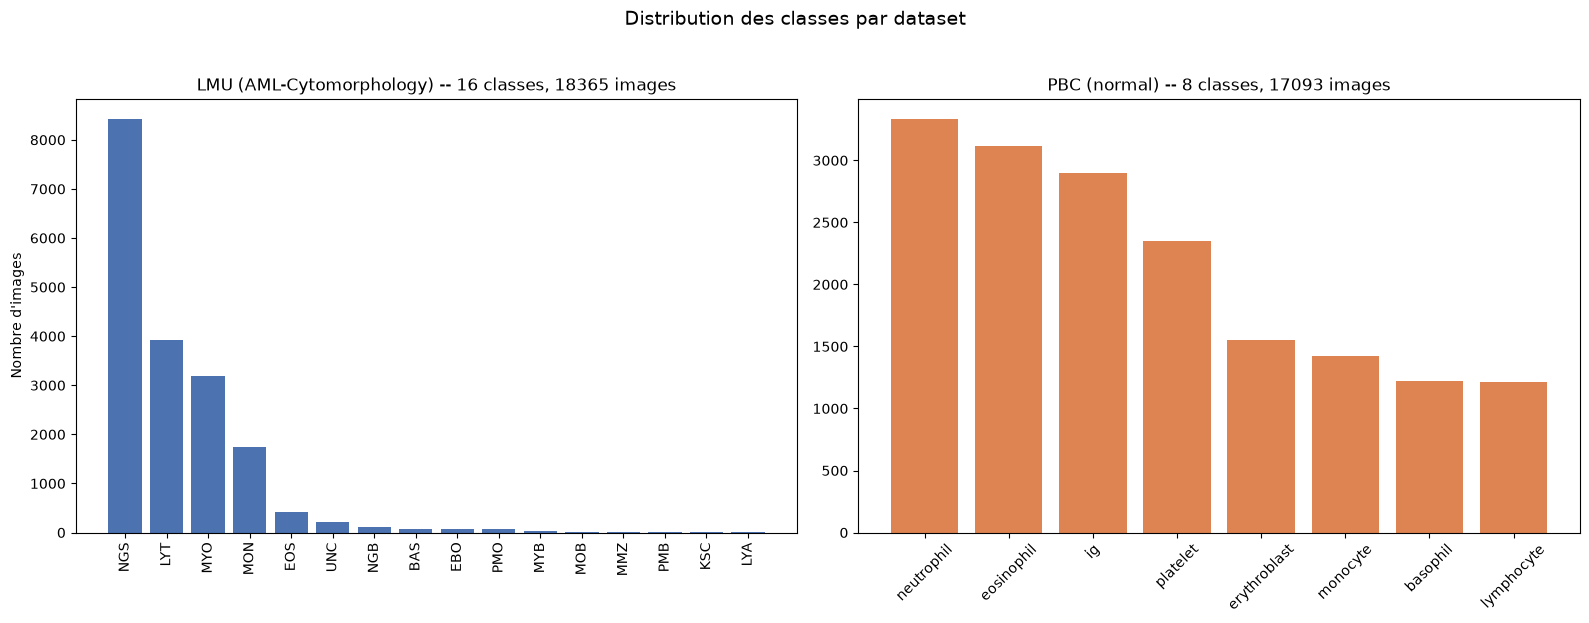

Ratio déséquilibre LMU (max/min) : 765.1x
Ratio déséquilibre PBC (max/min) : 2.7x


In [20]:
lmu_counts = lmu_meta.loc[lmu_meta["exists"], "final_label"].value_counts().sort_values(ascending=False)
pbc_counts = pbc_meta["final_label"].value_counts().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].bar(lmu_counts.index, lmu_counts.values, color="#4C72B0")
axes[0].set_title(f"LMU (AML-Cytomorphology) -- {len(lmu_counts)} classes, {lmu_counts.sum()} images")
axes[0].set_ylabel("Nombre d'images")
axes[0].tick_params(axis="x", rotation=90)

axes[1].bar(pbc_counts.index, pbc_counts.values, color="#DD8452")
axes[1].set_title(f"PBC (normal) -- {len(pbc_counts)} classes, {pbc_counts.sum()} images")
axes[1].tick_params(axis="x", rotation=45)

plt.suptitle("Distribution des classes par dataset", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

print(f"Ratio déséquilibre LMU (max/min) : {lmu_counts.max() / lmu_counts.min():.1f}x")
print(f"Ratio déséquilibre PBC (max/min) : {pbc_counts.max() / pbc_counts.min():.1f}x")


## 5. Qualité des annotations (LMU uniquement)

Le dataset LMU a fait l'objet d'une seconde vague d'annotation. On mesure ici le **taux de désaccord** entre le label de dossier d'origine et le label final retenu, globalement et par classe, ainsi que le nombre d'images classées `UNC` (non-classables).

Taux global de ré-étiquetage (désaccord avec la classe de dossier) : 2.05%
Images finalement marquées 'UNC' (non classables) : 208 (1.13%)


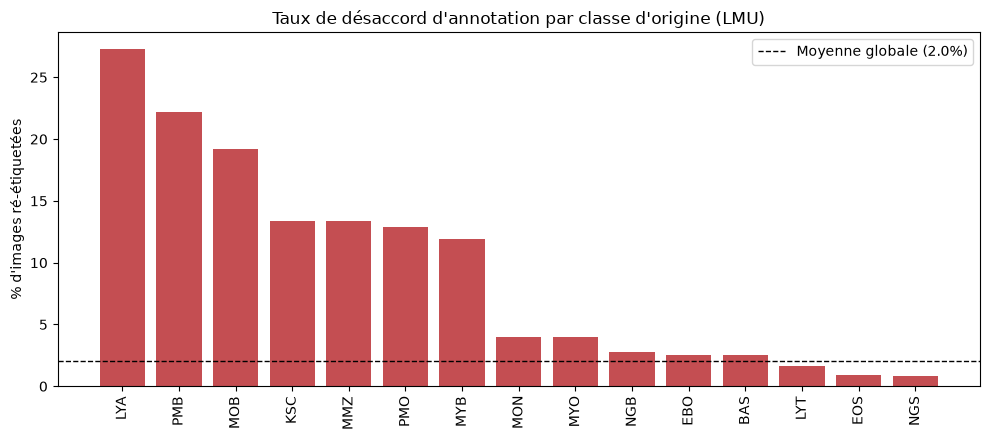

In [21]:
existing = lmu_meta[lmu_meta["exists"]]
relabel_rate = existing["relabeled"].mean() * 100
unc_count = (existing["final_label"] == "UNC").sum()

print(f"Taux global de ré-étiquetage (désaccord avec la classe de dossier) : {relabel_rate:.2f}%")
print(f"Images finalement marquées 'UNC' (non classables) : {unc_count} ({unc_count/len(existing)*100:.2f}%)")

per_class_relabel = existing.groupby("class_code")["relabeled"].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(per_class_relabel.index, per_class_relabel.values, color="#C44E52")
ax.set_ylabel("% d'images ré-étiquetées")
ax.set_title("Taux de désaccord d'annotation par classe d'origine (LMU)")
ax.tick_params(axis="x", rotation=90)
ax.axhline(relabel_rate, color="black", linestyle="--", linewidth=1, label=f"Moyenne globale ({relabel_rate:.1f}%)")
ax.legend()
plt.tight_layout()
plt.show()


## 6. Extraction des indicateurs de qualité image

Pour chaque image (échantillon de `SAMPLE_PER_CLASS` par classe, pour rester rapide sur de gros volumes), on calcule :
- **dimensions** (largeur, hauteur, ratio d'aspect)
- **poids du fichier** (Ko)
- **luminosité** (intensité moyenne en niveaux de gris)
- **contraste** (écart-type de l'intensité)
- **netteté** (variance du Laplacien -- un indicateur classique de flou : plus la valeur est basse, plus l'image est floue)

In [22]:
def extract_image_stats(path):
    """Calcule un ensemble d'indicateurs de qualité pour une image, sans la modifier."""
    try:
        file_size_kb = os.path.getsize(path) / 1024
        img = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if img is None:
            return None
        h, w, c = img.shape
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        return {
            "width": w, "height": h, "channels": c,
            "aspect_ratio": round(w / h, 3),
            "file_size_kb": file_size_kb,
            "brightness": float(np.mean(gray)),
            "contrast": float(np.std(gray)),
            "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        }
    except Exception:
        return None


def build_stats_sample(meta_df, sample_per_class=SAMPLE_PER_CLASS, seed=RANDOM_SEED):
    """Echantillonne (optionnel) puis calcule les indicateurs de qualité par image.
    NB: on evite groupby(...).apply(...) pour l'echantillonnage : selon la version de
    pandas (>=2.2), la colonne de groupement peut etre supprimee du resultat meme avec
    group_keys=False. On construit donc la liste d'index a garder manuellement."""
    d = meta_df[meta_df["exists"]].copy() if "exists" in meta_df else meta_df.copy()
    if sample_per_class is not None:
        sampled_idx = []
        for _, group in d.groupby("class_code"):
            n = min(len(group), sample_per_class)
            sampled_idx.extend(group.sample(n=n, random_state=seed).index.tolist())
        d = d.loc[sampled_idx]
    stats = d["path"].apply(extract_image_stats)
    stats_df = pd.DataFrame(list(stats), index=d.index)
    out = pd.concat([d, stats_df], axis=1).dropna(subset=["width"])
    return out


lmu_stats = build_stats_sample(lmu_meta)
pbc_stats = build_stats_sample(pbc_meta)

print(f"Indicateurs calculés -> LMU : {len(lmu_stats)} images | PBC : {len(pbc_stats)} images")
lmu_stats[["class_code","width","height","file_size_kb","brightness","contrast","sharpness"]].head()


Indicateurs calculés -> LMU : 1963 images | PBC : 2400 images


,class_code,width,height,file_size_kb,brightness,contrast,sharpness
30,BAS,400,400,625.150391,207.554831,55.445231,20.133400
0,BAS,400,400,625.150391,186.536219,50.148466,14.844416
22,BAS,400,400,625.150391,202.363231,52.661458,19.828891
31,BAS,400,400,625.150391,211.609369,52.704903,16.900959
18,BAS,400,400,625.150391,193.924419,52.999511,18.097844


## 7. Comparaison des dimensions

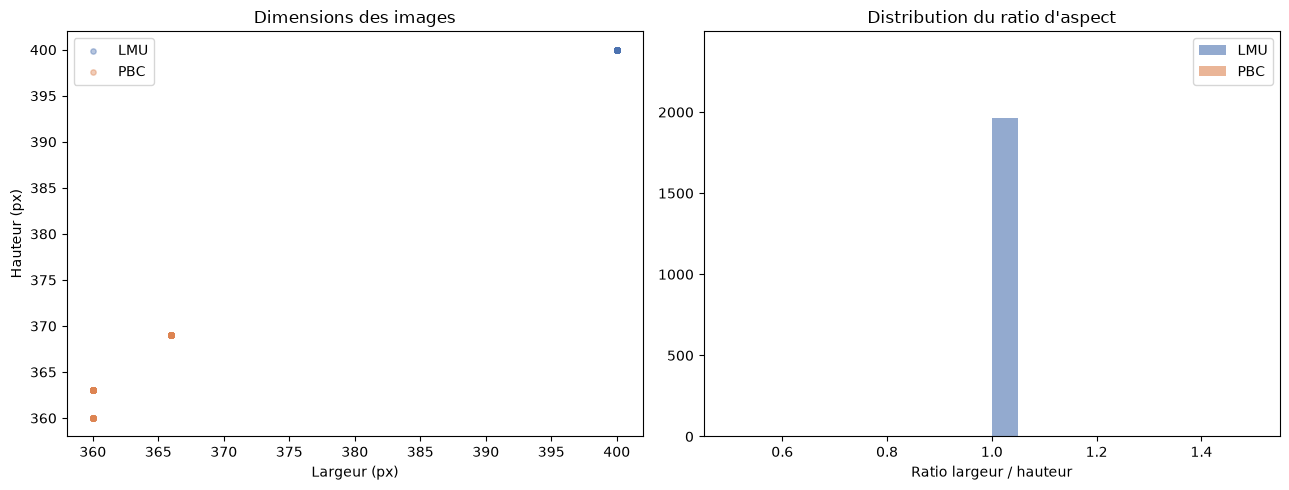

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(lmu_stats["width"], lmu_stats["height"], alpha=0.4, label="LMU", color="#4C72B0", s=15)
axes[0].scatter(pbc_stats["width"], pbc_stats["height"], alpha=0.4, label="PBC", color="#DD8452", s=15)
axes[0].set_xlabel("Largeur (px)")
axes[0].set_ylabel("Hauteur (px)")
axes[0].set_title("Dimensions des images")
axes[0].legend()

axes[1].hist(lmu_stats["aspect_ratio"], bins=20, alpha=0.6, label="LMU", color="#4C72B0")
axes[1].hist(pbc_stats["aspect_ratio"], bins=20, alpha=0.6, label="PBC", color="#DD8452")
axes[1].set_xlabel("Ratio largeur / hauteur")
axes[1].set_title("Distribution du ratio d'aspect")
axes[1].legend()

plt.tight_layout()
plt.show()


## 8. Comparaison du poids des fichiers

Le format `.tiff` (LMU, non compressé) est attendu beaucoup plus lourd que le `.jpg` (PBC, compressé avec pertes) -- échelle log pour bien visualiser les deux distributions.

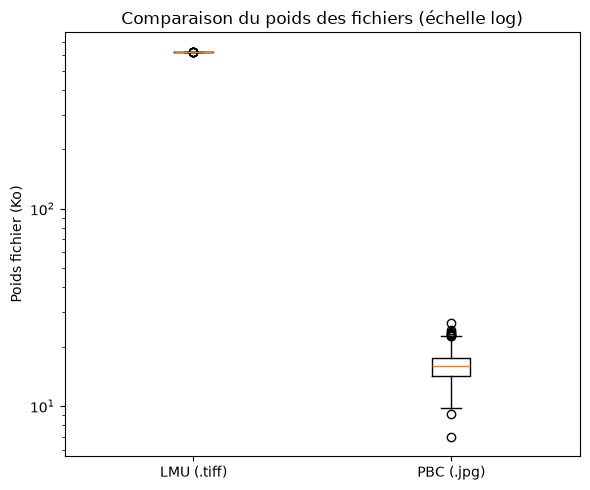

count    1963.000000
mean      625.151383
std         0.016595
min       625.150391
25%       625.150391
50%       625.150391
75%       625.150391
max       625.428711
Name: file_size_kb, dtype: float64

count    2400.000000
mean       15.934712
std         2.348651
min         6.991211
25%        14.274902
50%        15.944824
75%        17.606934
max        26.284180
Name: file_size_kb, dtype: float64


In [24]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.boxplot([lmu_stats["file_size_kb"], pbc_stats["file_size_kb"]], tick_labels=["LMU (.tiff)", "PBC (.jpg)"])
ax.set_ylabel("Poids fichier (Ko)")
ax.set_yscale("log")
ax.set_title("Comparaison du poids des fichiers (échelle log)")
plt.tight_layout()
plt.show()

print(lmu_stats["file_size_kb"].describe())
print()
print(pbc_stats["file_size_kb"].describe())


## 9. Luminosité, contraste et netteté

Ces trois indicateurs donnent une idée de la **qualité de numérisation/coloration** :
- une luminosité très haute ou très basse peut signaler une exposition/coloration mal calibrée
- un contraste faible peut indiquer une image "plate", difficile à segmenter
- une netteté (variance du Laplacien) faible signale un flou de mise au point

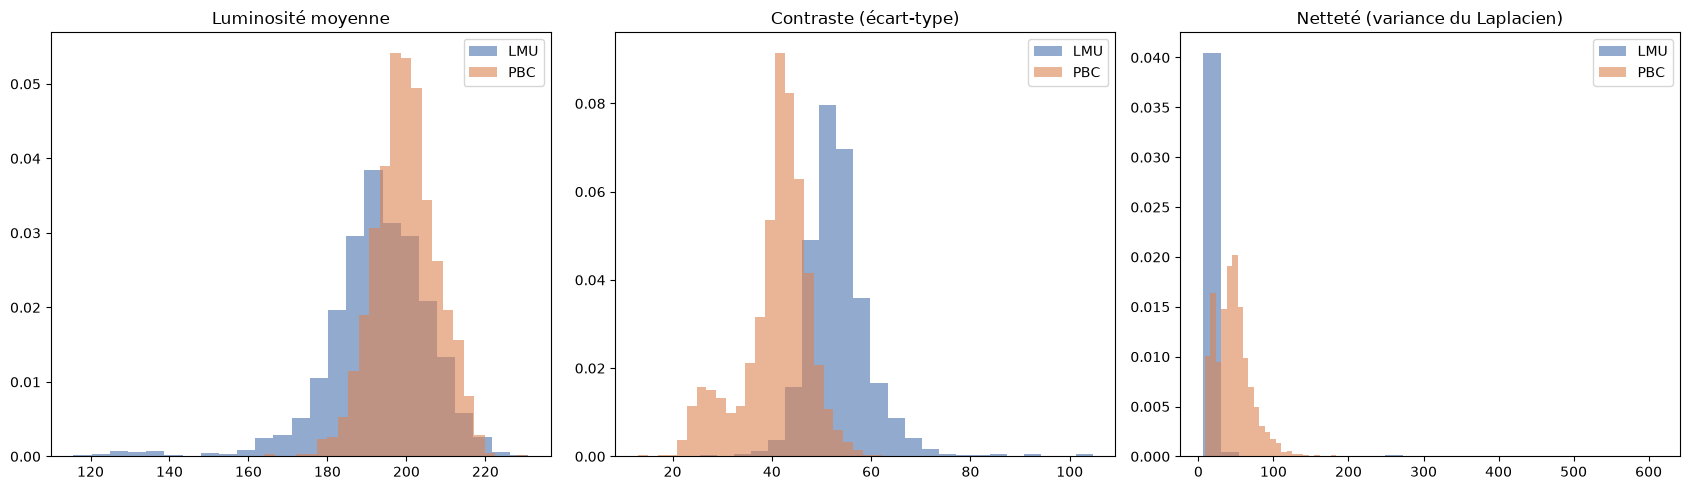

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = [
    ("brightness", "Luminosité moyenne"),
    ("contrast", "Contraste (écart-type)"),
    ("sharpness", "Netteté (variance du Laplacien)"),
]

for ax, (col, title) in zip(axes, metrics):
    ax.hist(lmu_stats[col], bins=25, alpha=0.6, label="LMU", color="#4C72B0", density=True)
    ax.hist(pbc_stats[col], bins=25, alpha=0.6, label="PBC", color="#DD8452", density=True)
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()


### Détection d'images potentiellement problématiques

On isole ici les images dont la netteté est anormalement basse (flou) au sein de l'échantillon -- utile pour un contrôle qualité rapide avant modélisation.

In [26]:
def flag_low_sharpness(stats_df, name, quantile=0.02):
    threshold = stats_df["sharpness"].quantile(quantile)
    flagged = stats_df[stats_df["sharpness"] <= threshold]
    print(f"{name} : seuil de netteté (percentile {quantile*100:.0f}%) = {threshold:.1f}")
    print(f"{name} : {len(flagged)} images potentiellement floues sur {len(stats_df)}")
    return flagged[["path", "class_code", "sharpness"]].sort_values("sharpness")

lmu_blurry = flag_low_sharpness(lmu_stats, "LMU")
pbc_blurry = flag_low_sharpness(pbc_stats, "PBC")
lmu_blurry.head()


LMU : seuil de netteté (percentile 2%) = 10.7
LMU : 40 images potentiellement floues sur 1963
PBC : seuil de netteté (percentile 2%) = 12.4
PBC : 48 images potentiellement floues sur 2400


,path,class_code,sharpness
9082,/media/jf/4C267D63267D4EC8/Liora/jul26_bds_blo...,MYO,5.831086
141,/media/jf/4C267D63267D4EC8/Liora/jul26_bds_blo...,EBO,6.290785
7530,/media/jf/4C267D63267D4EC8/Liora/jul26_bds_blo...,MYO,6.451688
8755,/media/jf/4C267D63267D4EC8/Liora/jul26_bds_blo...,MYO,6.549773
589,/media/jf/4C267D63267D4EC8/Liora/jul26_bds_blo...,KSC,7.129500


## 10. Tableau récapitulatif comparatif

In [27]:
# Correspondance entre les sous-classes fines du dataset PBC (préfixe du nom de fichier)
# et les classes du dataset LMU (PKG-AML-Cytomorphology)
PBC_TO_LMU = {
    # Cellules communes
    "BA": {"class_code": "BAS", "class_name": "Basophil"},
    "EO": {"class_code": "EOS", "class_name": "Eosinophil"},
    "ERB": {"class_code": "EBO", "class_name": "Erythroblast"},
    "LY": {"class_code": "LYT", "class_name": "Lymphocyte (typical)"},
    "MO": {"class_code": "MON", "class_name": "Monocyte"},
    # Neutrophiles
    "BNE": {"class_code": "NGB", "class_name": "Neutrophil (band)"},
    "SNE": {"class_code": "NGS", "class_name": "Neutrophil (segmented)"},
    "NEUTROPHIL": {"class_code": "NGS", "class_name": "Neutrophil (segmented)"},
    # Granulocytes immatures
    "PMY": {"class_code": "PMO", "class_name": "Promyelocyte"},
    "MY": {"class_code": "MYB", "class_name": "Myelocyte"},
    "MMY": {"class_code": "MMZ", "class_name": "Metamyelocyte"},
    "IG": {"class_code": "IG", "class_name": "Immature Granulocyte"},
    # Pas présent dans LMU
    "PLATELET": {"class_code": "PLATELET", "class_name": "Platelet"},
}

# Noms complets des classes LMU (cf. abbreviations.txt)
LMU_NAMES = {
    "BAS": "Basophil", "EBO": "Erythroblast", "EOS": "Eosinophil", "KSC": "Smudge cell",
    "LYA": "Lymphocyte (atypical)", "LYT": "Lymphocyte (typical)", "MMZ": "Metamyelocyte",
    "MOB": "Monoblast", "MON": "Monocyte", "MYB": "Myelocyte", "MYO": "Myeloblast",
    "NGB": "Neutrophil (band)", "NGS": "Neutrophil (segmented)", "PMB": "Promyelocyte (bilobed)",
    "PMO": "Promyelocyte",
}


def extract_pbc_subclass(filename_stem):
    """Extrait le code de sous-classe PBC à partir du préfixe du nom de fichier
    (ex: 'BA_47' -> 'BA', 'PLATELET_516' -> 'PLATELET')."""
    return filename_stem.split("_")[0].upper()


# --- PBC : sous-classe fine (préfixe fichier) -> classe commune (code + nom LMU) ---
pbc_stats["pbc_subclass"] = pbc_stats["path"].apply(lambda p: extract_pbc_subclass(Path(p).stem))
pbc_stats["common_class_code"] = pbc_stats["pbc_subclass"].map(
    lambda c: PBC_TO_LMU.get(c, {}).get("class_code", c)
)
pbc_stats["common_class_name"] = pbc_stats["pbc_subclass"].map(
    lambda c: PBC_TO_LMU.get(c, {}).get("class_name", c)
)

# --- LMU : déjà dans la nomenclature commune ---
lmu_stats["common_class_code"] = lmu_stats["class_code"]
lmu_stats["common_class_name"] = lmu_stats["class_code"].map(LMU_NAMES).fillna(lmu_stats["class_code"])


def summarize_by_class(stats_df, dataset_label):
    """Agrège les indicateurs de qualité par classe commune, pour un dataset donné."""
    rows = []
    for code, g in stats_df.groupby("common_class_code"):
        rows.append({
            "common_class_code": code,
            "common_class_name": g["common_class_name"].iloc[0],
            f"Nb images ({dataset_label})": len(g),
            f"Résolution moyenne ({dataset_label})": f"{g['width'].mean():.0f} x {g['height'].mean():.0f}",
            f"Poids moyen Ko ({dataset_label})": round(g["file_size_kb"].mean(), 1),
            f"Luminosité ({dataset_label})": round(g["brightness"].mean(), 1),
            f"Contraste ({dataset_label})": round(g["contrast"].mean(), 1),
            f"Netteté ({dataset_label})": round(g["sharpness"].mean(), 1),
        })
    return pd.DataFrame(rows).set_index(["common_class_code", "common_class_name"])


lmu_class_summary = summarize_by_class(lmu_stats, "LMU")
pbc_class_summary = summarize_by_class(pbc_stats, "PBC")

# Jointure externe : les classes absentes d'un des deux datasets apparaissent en NaN
# (ex: KSC/LYA/MOB/MYO/PMB/NGS-only côté LMU, IG/PLATELET côté PBC)
summary_df = lmu_class_summary.join(pbc_class_summary, how="outer").sort_index()

summary_df


,,Nb images (LMU),Résolution moyenne (LMU),Poids moyen Ko (LMU),Luminosité (LMU),Contraste (LMU),Netteté (LMU),Nb images (PBC),Résolution moyenne (PBC),Poids moyen Ko (PBC),Luminosité (PBC),Contraste (PBC),Netteté (PBC)
common_class_code,common_class_name,,,,,,,,,,,,
BAS,Basophil,79.0,400 x 400,625.2,192.1,54.8,23.8,300.0,360 x 363,17.2,197.4,46.5,73.5
EBO,Erythroblast,78.0,400 x 400,625.2,203.2,49.1,23.7,300.0,360 x 363,13.6,205.5,37.6,27.3
EOS,Eosinophil,300.0,400 x 400,625.2,189.9,53.2,19.9,300.0,360 x 363,16.8,198.1,43.0,47.7
IG,Immature Granulocyte,NaN,NaN,NaN,NaN,NaN,NaN,14.0,360 x 360,14.9,194.3,40.0,15.8
KSC,Smudge cell,15.0,400 x 400,625.2,195.4,41.1,15.9,NaN,NaN,NaN,NaN,NaN,NaN
LYA,Lymphocyte (atypical),11.0,400 x 400,625.2,197.2,57.3,17.4,NaN,NaN,NaN,NaN,NaN,NaN
LYT,Lymphocyte (typical),300.0,400 x 400,625.2,200.6,51.7,15.2,300.0,360 x 363,15.0,200.1,42.0,36.0
MMZ,Metamyelocyte,15.0,400 x 400,625.2,194.3,57.1,18.8,111.0,360 x 363,17.0,197.5,44.8,56.2
MOB,Monoblast,26.0,400 x 400,625.2,182.9,55.0,15.7,NaN,NaN,NaN,NaN,NaN,NaN


## 11. Aperçu visuel d'échantillons par classe

Une vérification visuelle rapide complète les statistiques : on affiche une image aléatoire par classe pour chaque dataset.

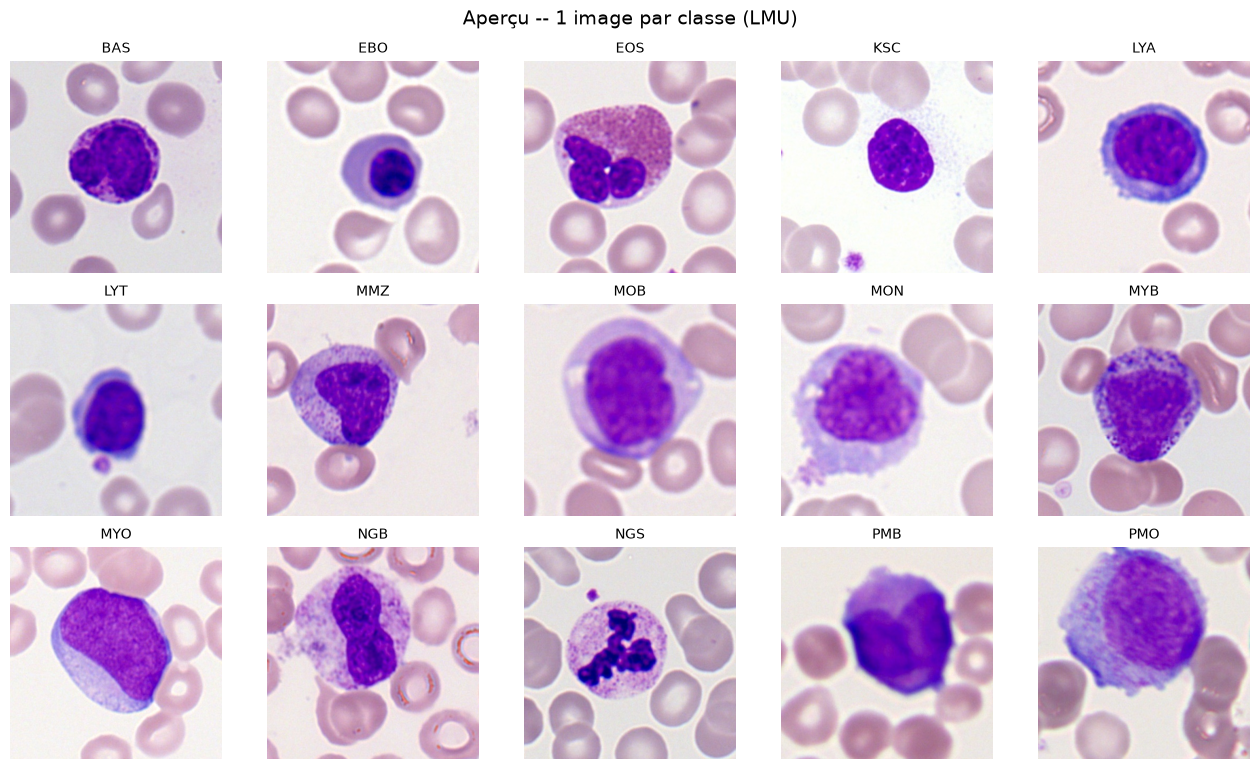

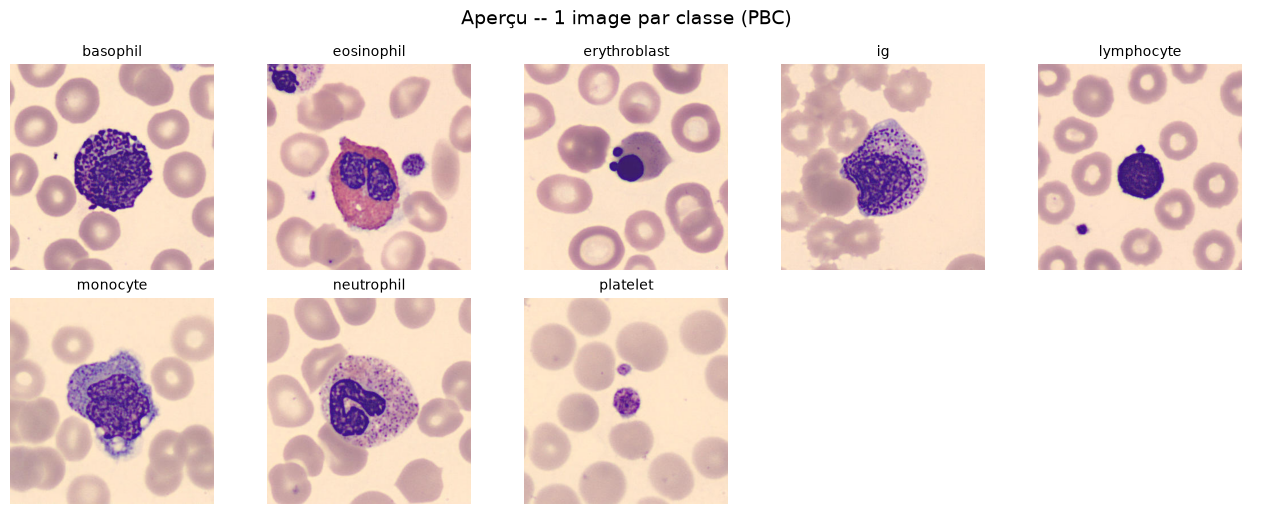

In [28]:
def show_sample_grid(meta_df, title, n_cols=5, seed=RANDOM_SEED):
    classes = sorted(meta_df["class_code"].unique())
    n_rows = int(np.ceil(len(classes) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.6, n_rows * 2.6))
    axes = np.array(axes).reshape(-1)

    rng = np.random.RandomState(seed)
    for i, cls in enumerate(classes):
        subset = meta_df[(meta_df["class_code"] == cls) & (meta_df.get("exists", True) == True)]
        if len(subset) == 0:
            continue
        sample_path = subset["path"].iloc[rng.randint(len(subset))]
        img = cv2.cvtColor(cv2.imread(str(sample_path)), cv2.COLOR_BGR2RGB)
        axes[i].imshow(img)
        axes[i].set_title(cls, fontsize=10)
        axes[i].axis("off")

    for j in range(len(classes), len(axes)):
        axes[j].axis("off")

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

show_sample_grid(lmu_meta, "Aperçu -- 1 image par classe (LMU)")
show_sample_grid(pbc_meta, "Aperçu -- 1 image par classe (PBC)")


## Conclusion

Ce notebook fournit une base d'exploration statistique reproductible pour comparer la **qualité** et la **structure** des deux datasets :
- déséquilibre des classes (souvent bien plus marqué sur des datasets cliniques comme LMU)
- écarts de résolution/poids liés au format (`.tiff` non compressé vs `.jpg` compressé)
- écarts de luminosité/contraste/netteté pouvant révéler des différences de protocole de numérisation entre les deux sources
- fiabilité des annotations LMU (taux de ré-étiquetage, images `UNC`)

Ces éléments sont à prendre en compte avant toute étape de modélisation (ex. harmonisation de résolution, normalisation de couleur, pondération des classes).